# SS3 Part B: Applying the SS2 Logistic Regression Method

## Purpose
This notebook applies the final modelling method selected in SS2, logistic regression, to the STADIOEquities client data. The goal is to predict whether a newly registered client makes a deposit within 30 days, using only information available by the end of day 3.

The notebook is organised into the required assessment components. Run the cells from top to bottom. The results and discussion section interprets the model evaluation, baseline comparison, subgroup results and limitations.

## 1. Setup and imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    classification_report, precision_recall_curve, roc_curve
)
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix

pd.set_option("display.max_columns", 100)

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("CAP182_SS3_Client_Data") / "data"
print("Data folder:", DATA_DIR.resolve())
print("CSV files:", sorted(p.name for p in DATA_DIR.glob("*.csv")))

Data folder: C:\Users\cash\Downloads\stadioequities\stadioequities\data
CSV files: ['table1_client_demographics_registration.csv', 'table2_onboarding_kyc_day3.csv', 'table3_app_web_behaviour_day3.csv', 'table4_funding_account_status.csv', 'table5_marketing_acquisition.csv']


## 2. Dataset loading

The five client CSV files are loaded and inspected in this section. Table 1 initially contains **24,259 rows**. After removing **72 exact duplicate rows**, it contains **24,187 unique clients**, which are merged one-to-one across the five tables.

The target is `deposited_within_30_days`: **class 0** means no deposit within 30 days, and **class 1** means a deposit within 30 days. After merging, there are **13,948 class 0 clients (57.7%)** and **10,239 class 1 clients (42.3%)**. This is a **mild class imbalance**, with approximately **1.4 non-depositors for every depositor**. Accuracy is therefore interpreted alongside precision, recall, F1-score and ranking metrics.

The initial inventory below records each table's size, columns, duplicate rows and missing values before the data is cleaned and merged.

In [2]:
files = {
    "table1": "table1_client_demographics_registration.csv",
    "table2": "table2_onboarding_kyc_day3.csv",
    "table3": "table3_app_web_behaviour_day3.csv",
    "table4": "table4_funding_account_status.csv",
    "table5": "table5_marketing_acquisition.csv",
}

tables = {}
for name, filename in files.items():
    df = pd.read_csv(DATA_DIR / filename)
    tables[name] = df
    print(f"\n{'='*80}\n{name}: {filename}")
    print("Shape (rows, columns):", df.shape)
    print("\nColumn information:")
    df.info()
    print("\nNull counts:")
    display(df.isna().sum().to_frame("null_count"))
    print("Fully duplicated rows:", df.duplicated().sum())
    print("Repeated client_id values:", df["client_id"].duplicated().sum())


table1: table1_client_demographics_registration.csv
Shape (rows, columns): (24259, 7)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 24259 entries, 0 to 24258
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   client_id               24259 non-null  str    
 1   registration_date       24259 non-null  str    
 2   age                     24106 non-null  float64
 3   province                24259 non-null  str    
 4   stated_investment_goal  23553 non-null  str    
 5   stated_risk_appetite    24259 non-null  str    
 6   acquisition_channel     24259 non-null  str    
dtypes: float64(1), str(6)
memory usage: 2.7 MB

Null counts:


,null_count
client_id,0
registration_date,0
age,153
province,0
stated_investment_goal,706
stated_risk_appetite,0
acquisition_channel,0


Fully duplicated rows: 72
Repeated client_id values: 72

table2: table2_onboarding_kyc_day3.csv
Shape (rows, columns): (24187, 5)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 5 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   client_id                        24187 non-null  str    
 1   kyc_status_day3                  24187 non-null  str    
 2   onboarding_steps_completed_day3  24187 non-null  int64  
 3   step_last_abandoned              4610 non-null   str    
 4   time_to_kyc_complete_hours       12063 non-null  float64
dtypes: float64(1), int64(1), str(3)
memory usage: 1.5 MB

Null counts:


,null_count
client_id,0
kyc_status_day3,0
onboarding_steps_completed_day3,0
step_last_abandoned,19577
time_to_kyc_complete_hours,12124


Fully duplicated rows: 0
Repeated client_id values: 0

table3: table3_app_web_behaviour_day3.csv
Shape (rows, columns): (24187, 6)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   client_id                       24187 non-null  str    
 1   time_to_first_session_hours     24187 non-null  float64
 2   first_session_duration_minutes  23894 non-null  float64
 3   screens_viewed_first_session    24187 non-null  int64  
 4   sessions_by_day3                24187 non-null  int64  
 5   device_type                     24187 non-null  str    
dtypes: float64(2), int64(2), str(2)
memory usage: 1.5 MB

Null counts:


...

Fully duplicated rows: 0
Repeated client_id values: 0

table4: table4_funding_account_status.csv
Shape (rows, columns): (24187, 4)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   client_id                 24187 non-null  str  
 1   deposited_within_30_days  24187 non-null  int64
 2   date_of_first_deposit     10239 non-null  str  
 3   account_status_day30      24187 non-null  str  
dtypes: int64(1), str(3)
memory usage: 1.4 MB

Null counts:


,null_count
client_id,0
deposited_within_30_days,0
date_of_first_deposit,13948
account_status_day30,0


Fully duplicated rows: 0
Repeated client_id values: 0

table5: table5_marketing_acquisition.csv
Shape (rows, columns): (24187, 3)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   client_id              24187 non-null  str    
 1   acquisition_cost_zar   24187 non-null  float64
 2   nudge_engagement_day3  24187 non-null  str    
dtypes: float64(1), str(2)
memory usage: 961.0 KB

Null counts:


,null_count
client_id,0
acquisition_cost_zar,0
nudge_engagement_day3,0


Fully duplicated rows: 0
Repeated client_id values: 0


### Table descriptions
- **Table 1** contains client registration details and demographics, including registration date, age, province, investment goal, risk appetite and acquisition channel.
- **Table 2** contains onboarding and Know Your Customer (KYC) progress measured by day 3.
- **Table 3** contains early app/web behaviour by day 3, such as first-session timing, session duration, screens viewed, session count and device type.
- **Table 4** contains the target `deposited_within_30_days`, as well as later information about deposit date and day-30 account status. The later fields must not be used as predictors.
- **Table 5** contains acquisition cost and day-3 engagement with nudges.

### Check client ID sets before merging

In [3]:
id_sets = {name: set(df["client_id"].dropna()) for name, df in tables.items()}
reference_name = "table2"
reference_ids = id_sets[reference_name]
comparison_rows = []
for name, ids in id_sets.items():
    if name == reference_name:
        continue
    comparison_rows.append({
        "table compared with table2": name,
        "rows": len(tables[name]),
        "unique non-null client IDs": len(ids),
        "IDs in this table but not table2": len(ids - reference_ids),
        "IDs in table2 but not this table": len(reference_ids - ids),
        "shared IDs with table2": len(ids & reference_ids),
    })
display(pd.DataFrame(comparison_rows).set_index("table compared with table2"))
print("Table 1 fully duplicated rows:", tables["table1"].duplicated().sum())
print("Table 1 repeated client IDs:", tables["table1"]["client_id"].duplicated().sum())
display(tables["table1"][tables["table1"].duplicated(keep=False)].sort_values("client_id").head(20))

,rows,unique non-null client IDs,IDs in this table but not table2,IDs in table2 but not this table,shared IDs with table2
table compared with table2,,,,,
table1,24259,24187,0,0,24187
table3,24187,24187,0,0,24187
table4,24187,24187,0,0,24187
table5,24187,24187,0,0,24187


Table 1 fully duplicated rows: 72
Table 1 repeated client IDs: 72


,client_id,registration_date,age,province,stated_investment_goal,stated_risk_appetite,acquisition_channel
764,CU-0280764,2026-02-13,22.0,Mpumalanga,Wealth building,Medium,Search ad
24217,CU-0280764,2026-02-13,22.0,Mpumalanga,Wealth building,Medium,Search ad
892,CU-0280892,2024-11-02,25.0,Western Cape,Learning/exploring,High,Social media ad
24247,CU-0280892,2024-11-02,25.0,Western Cape,Learning/exploring,High,Social media ad
1332,CU-0281332,2024-08-10,43.0,Western Cape,Retirement,High,Referral
24193,CU-0281332,2024-08-10,43.0,Western Cape,Retirement,High,Referral
1805,CU-0281805,2025-04-27,28.0,Free State,Wealth building,Medium,Influencer
24210,CU-0281805,2025-04-27,28.0,Free State,Wealth building,Medium,Influencer
3515,CU-0283515,2025-12-15,24.0,Gauteng,Short-term growth,High,Search ad
24190,CU-0283515,2025-12-15,24.0,Gauteng,Short-term growth,High,Search ad


## 3. Dataset preprocessing

This section covers ID checks, cleaning, merging, target/predictor definition, leakage prevention, chronological splitting, and the preprocessing pipeline. These steps are needed to create a consistent modelling dataset and to avoid using information that would not be available at the end of day 3.

In [4]:
# Work on copies so the original loaded tables remain unchanged.
t1 = tables["table1"].copy()
t2 = tables["table2"].copy()
t3 = tables["table3"].copy()
t4 = tables["table4"].copy()
t5 = tables["table5"].copy()

# Standardise whitespace in text columns and IDs.
for df in [t1, t2, t3, t4, t5]:
    df["client_id"] = df["client_id"].astype("string").str.strip()
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].astype("string").str.strip()

# Remove exact duplicate rows in Table 1 only after recording their count above.
t1 = t1.drop_duplicates()

# Check if client IDs are unique before merging.
for name, df in {"table1": t1, "table2": t2, "table3": t3, "table4": t4, "table5": t5}.items():
    print(name, "rows:", len(df), "duplicate IDs:", df["client_id"].duplicated().sum())

# Keep one row per client in each table; stop if duplicates remain because they need investigation.
assert all(not df["client_id"].duplicated().any() for df in [t1, t2, t3, t4, t5]), \
    "At least one table still has repeated client_id values. Inspect before merging."

data = t1.merge(t2, on="client_id", how="inner", validate="one_to_one")
data = data.merge(t3, on="client_id", how="inner", validate="one_to_one")
data = data.merge(t4, on="client_id", how="inner", validate="one_to_one")
data = data.merge(t5, on="client_id", how="inner", validate="one_to_one")

data["registration_date"] = pd.to_datetime(data["registration_date"], errors="coerce")
print("Merged shape:", data.shape)
print("Unique clients:", data["client_id"].nunique())
display(data.head())

table1 rows: 24187 duplicate IDs: 0
table2 rows: 24187 duplicate IDs: 0
table3 rows: 24187 duplicate IDs: 0
table4 rows: 24187 duplicate IDs: 0
table5 rows: 24187 duplicate IDs: 0
Merged shape: (24187, 21)
Unique clients: 24187


,client_id,registration_date,age,province,stated_investment_goal,stated_risk_appetite,acquisition_channel,kyc_status_day3,onboarding_steps_completed_day3,step_last_abandoned,time_to_kyc_complete_hours,time_to_first_session_hours,first_session_duration_minutes,screens_viewed_first_session,sessions_by_day3,device_type,deposited_within_30_days,date_of_first_deposit,account_status_day30,acquisition_cost_zar,nudge_engagement_day3
0,CU-0280000,2025-06-21,33.0,Gauteng,Learning/exploring,Low,Organic/direct,Completed,5,<NA>,2.4,0.64,4.9,1,1,Android,0,<NA>,Never funded,110.37,Clicked
1,CU-0280001,2025-09-13,35.0,Free State,Short-term growth,Medium,Social media ad,In Progress,1,<NA>,NaN,0.17,2.9,7,3,iOS,0,<NA>,Never funded,249.39,Opened
2,CU-0280002,2024-12-27,29.0,Northern Cape,Wealth building,Low,Social media ad,Completed,5,<NA>,2.1,0.18,13.5,1,3,Web,1,2025-01-21,Funded then dormant,225.47,Clicked
3,CU-0280003,2026-05-24,38.0,KwaZulu-Natal,Wealth building,Medium,Referral,Completed,5,<NA>,3.1,1.51,6.1,10,3,Web,1,2026-05-25,Funded & active,0.00,Opened
4,CU-0280004,2025-10-05,42.0,Western Cape,Short-term growth,Medium,Search ad,Completed,5,<NA>,9.3,3.54,11.0,8,8,Android,1,2025-11-02,Funded & active,133.36,Opened


### Define the target and predictors

The target is `deposited_within_30_days`. Predictors are restricted to information available by the end of day 3. We exclude `date_of_first_deposit` and `account_status_day30` because they are only known after the prediction point and would leak future information. We exclude `client_id` because it is an identifier. The raw `registration_date` is used only to order and split records chronologically; only the coarser `registration_month` is retained as a predictor.

`registration_month` is retained as a coarse registration-season feature because signup patterns may vary across months. It is derived from the registration date, which is available at the prediction point. Month is encoded as an integer from 1 to 12, so this representation does not fully capture the cyclical relationship between December and January; this is a limitation to consider in future feature testing.

In [5]:
target = "deposited_within_30_days"
data = data.dropna(subset=[target, "registration_date"]).copy()
data[target] = data[target].astype(int)

excluded = [
    "client_id", target, "registration_date",
    "date_of_first_deposit", "account_status_day30",
]
X = data.drop(columns=[c for c in excluded if c in data.columns]).copy()
X["registration_month"] = data["registration_date"].dt.month
y = data[target].copy()

# Convert pandas nullable string values to ordinary object/np.nan for sklearn imputers.
for col in X.select_dtypes(include=["object", "string"]).columns:
    X[col] = X[col].astype(object).where(X[col].notna(), np.nan)

# Treat structurally absent KYC fields according to their meaning, not the mode/median.
# An absent abandoned step means no abandonment step was recorded for that client.
if "step_last_abandoned" in X.columns:
    X["step_last_abandoned"] = X["step_last_abandoned"].fillna("None / not abandoned").astype("object")
# KYC completion time exists only for clients who completed KYC; retain missingness
# and add an explicit indicator before numeric imputation in the pipeline.
if "time_to_kyc_complete_hours" in X.columns:
    X["kyc_time_missing"] = X["time_to_kyc_complete_hours"].isna().astype(int)

print("Instances:", len(data))
print("Predictor columns:", len(X.columns))
print("Raw registration_date included as predictor:", "registration_date" in X.columns)
print("Target classes:")
display(y.value_counts().rename(index={0: "No deposit within 30 days", 1: "Deposit within 30 days"}).to_frame("count"))
print("Target proportions:")
display(y.value_counts(normalize=True).rename(index={0: "No deposit within 30 days", 1: "Deposit within 30 days"}).to_frame("proportion"))

if "age" in X.columns:
    implausible_age = X["age"].notna() & ~X["age"].between(18, 100)
    print("Age values outside 18-100:", int(implausible_age.sum()))
    X.loc[implausible_age, "age"] = np.nan

# Sort predictors and labels together by registration date. Keep dates separately for splitting.
order = np.argsort(data["registration_date"].to_numpy(), kind="stable")
X = X.iloc[order].reset_index(drop=True)
y = y.iloc[order].reset_index(drop=True)
ordered_dates = data["registration_date"].iloc[order].reset_index(drop=True)

# Split at unique date boundaries so clients registered on one date stay in one subset.
unique_dates = np.sort(ordered_dates.dropna().unique())
train_date_index = int(len(unique_dates) * 0.70)
valid_date_index = int(len(unique_dates) * 0.85)
train_cutoff = pd.Timestamp(unique_dates[train_date_index])
valid_cutoff = pd.Timestamp(unique_dates[valid_date_index])
train_mask = ordered_dates < train_cutoff
valid_mask = (ordered_dates >= train_cutoff) & (ordered_dates < valid_cutoff)
test_mask = ordered_dates >= valid_cutoff
X_train, y_train = X.loc[train_mask].copy(), y.loc[train_mask].copy()
X_valid, y_valid = X.loc[valid_mask].copy(), y.loc[valid_mask].copy()
X_test, y_test = X.loc[test_mask].copy(), y.loc[test_mask].copy()

for label, mask in [("Training", train_mask), ("Validation", valid_mask), ("Unseen test", test_mask)]:
    dates = ordered_dates.loc[mask]
    features = X.loc[mask]
    print(f"{label}: {features.shape}; dates {dates.min().date()} to {dates.max().date()}")
assert set(ordered_dates.loc[train_mask]).isdisjoint(set(ordered_dates.loc[valid_mask]))
assert set(ordered_dates.loc[valid_mask]).isdisjoint(set(ordered_dates.loc[test_mask]))
assert set(ordered_dates.loc[train_mask]).isdisjoint(set(ordered_dates.loc[test_mask]))
assert "registration_date" not in X_train.columns

Instances: 24187
Predictor columns: 18
Raw registration_date included as predictor: False
Target classes:


,count
deposited_within_30_days,
No deposit within 30 days,13948
Deposit within 30 days,10239


Target proportions:


,proportion
deposited_within_30_days,
No deposit within 30 days,0.576673
Deposit within 30 days,0.423327


Age values outside 18-100: 17
Training: (16828, 18); dates 2024-06-01 to 2025-11-23
Validation: (3659, 18); dates 2025-11-24 to 2026-03-19
Unseen test: (3700, 18); dates 2026-03-20 to 2026-07-14


### Build the preprocessing pipeline

Numeric predictors are median-imputed and standardised. Categorical predictors are imputed with their most frequent training value and one-hot encoded. The pipeline is fitted inside cross-validation folds to reduce leakage from validation folds.

### Why these preprocessing choices?
- Numeric predictors are median-imputed and scaled, while categorical predictors are imputed with the most frequent value and one-hot encoded.
- These transformations are placed in a scikit-learn pipeline so that each cross-validation fold learns its own imputation, scaling and encoding parameters from its training portion only.
- `step_last_abandoned` is filled with an explicit “None / not abandoned” category because the field is structurally absent when a client has not abandoned onboarding.
- `time_to_kyc_complete_hours` is missing by definition for clients who did not complete KYC. A separate missingness indicator preserves this information, while median imputation allows the numeric feature to be used by logistic regression.
- Implausible ages outside 18 to 100 are treated as missing before imputation, rather than allowing them to distort the fitted model.

In [6]:
# Identify numeric and categorical columns from the training data only.
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

## 4. Model training

Logistic regression is used because it is the final method selected in SS2 and produces both class predictions and predicted probabilities.

The hyperparameter search tests `C = 0.01, 0.1, 1, 10`. These values are spaced logarithmically across a range from stronger regularisation (`0.01`) to weaker regularisation (`10`), allowing the search to test simpler and more flexible models without an excessively large grid. The best value, `C = 0.1`, lies inside the tested range rather than at either boundary, so the search did not simply select the strongest or weakest option tested.

Both `class_weight=None` and `class_weight="balanced"` are compared instead of assuming that weighting is necessary. Although the target classes are mildly imbalanced, comparing both options lets the training data determine whether weighting improves cross-validation ROC-AUC.

The `liblinear` solver is suitable for this binary logistic regression task and supports the tested class-weight options. `max_iter=2000` gives the optimiser enough iterations to converge for the encoded feature set. `random_state=42` makes the estimator's random behaviour reproducible. Five-fold `TimeSeriesSplit` preserves chronological order within the training period, so each fold evaluates on a later portion than the portion used to fit it. ROC-AUC is the selection score because it evaluates how well predicted probabilities rank depositors above non-depositors across thresholds, rather than relying on one arbitrary threshold.

All preprocessing is part of the pipeline, so imputation, scaling and encoding are learned from each training fold rather than from the full dataset.

After running the search, compare the best cross-validation ROC-AUC obtained with each class-weight option. If the difference is very small (around 0.00002 in the current reported table), treat the two options as effectively similar on this selection metric; do not describe class weighting as a meaningful improvement on ROC-AUC alone. The balanced option can still affect the chosen decision boundary and classification metrics.

In [7]:
# Tune regularisation strength on the training period only.
# class_weight is compared rather than assumed to be best.
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, solver="liblinear", random_state=42)),
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
}

# TimeSeriesSplit respects ordering within the training data.
cv = TimeSeriesSplit(n_splits=5)
search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
search.fit(X_train, y_train)

print("Best training-CV ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)
best_model = search.best_estimator_


# Summarise the size of the difference between class-weight choices after fitting.
cv_summary = pd.DataFrame(search.cv_results_)
cv_summary["class_weight_label"] = cv_summary["param_model__class_weight"].map(
    lambda value: "Balanced" if value == "balanced" else "Unweighted"
)
best_by_weight = cv_summary.sort_values("mean_test_score", ascending=False).groupby("class_weight_label").first()
if {"Balanced", "Unweighted"}.issubset(set(best_by_weight.index)):
    weight_gap = abs(best_by_weight.loc["Balanced", "mean_test_score"] - best_by_weight.loc["Unweighted", "mean_test_score"])
    print(f"Absolute ROC-AUC difference between best weighted and unweighted settings: {weight_gap:.5f}")


Best training-CV ROC-AUC: 0.8749
Best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Absolute ROC-AUC difference between best weighted and unweighted settings: 0.00002


## 5. Model validation on validation and unseen test subsets

Training-only time-series cross-validation results:


,param_model__C,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
3,0.10,balanced,0.87486,0.00358,1
2,0.10,NaN,0.87484,0.00364,2
4,1.00,NaN,0.87468,0.00361,3
5,1.00,balanced,0.87466,0.00358,4
6,10.00,NaN,0.87438,0.00372,5
7,10.00,balanced,0.87436,0.00370,6
1,0.01,balanced,0.87410,0.00365,7
0,0.01,NaN,0.87391,0.00378,8


Validation-selected threshold (maximum validation F1): 0.489


,n,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc_average_precision,brier_score
subset,,,,,,,,,
Training,16828,0.489,0.7970,0.7143,0.8695,0.7843,0.8772,0.8155,0.1414
Validation,3659,0.489,0.7928,0.7129,0.8648,0.7816,0.8715,0.8070,0.1444
Unseen test,3700,0.489,0.7965,0.7054,0.8719,0.7799,0.8748,0.8036,0.1418


Unseen test classification report at validation-selected threshold:
                           precision    recall  f1-score   support

No deposit within 30 days       0.89      0.74      0.81      2170
   Deposit within 30 days       0.71      0.87      0.78      1530

                 accuracy                           0.80      3700
                macro avg       0.80      0.81      0.80      3700
             weighted avg       0.81      0.80      0.80      3700

KYC rule baseline on unseen test:
accuracy     0.7927
precision    0.7100
recall       0.8431
f1           0.7708
dtype: float64


,metric,estimate,bootstrap 95% CI lower,bootstrap 95% CI upper
0,Test ROC-AUC,0.8748,0.8641,0.8862
1,Test F1 at selected threshold,0.7799,0.7640,0.7964
2,Accuracy difference: model minus KYC rule,0.0038,-0.0038,0.0111


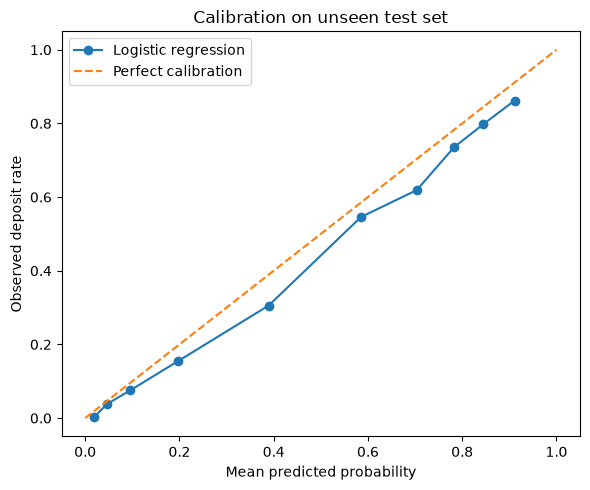

Unseen-test confusion counts at threshold 0.489:
True negatives (TN): 1613
False positives (FP): 557
False negatives (FN): 196
True positives (TP): 1334


In [8]:
def evaluate_model(model, X_part, y_part, label, threshold=0.5):
    probabilities = model.predict_proba(X_part)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    metrics = {
        "subset": label, "n": len(y_part), "threshold": threshold,
        "accuracy": accuracy_score(y_part, predictions),
        "precision": precision_score(y_part, predictions, zero_division=0),
        "recall": recall_score(y_part, predictions, zero_division=0),
        "f1": f1_score(y_part, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_part, probabilities) if y_part.nunique() == 2 else np.nan,
        "pr_auc_average_precision": average_precision_score(y_part, probabilities) if y_part.nunique() == 2 else np.nan,
        "brier_score": brier_score_loss(y_part, probabilities),
    }
    return metrics, probabilities, predictions

# Inspect every hyperparameter combination; very small ROC-AUC differences should not be overinterpreted.
cv_results = pd.DataFrame(search.cv_results_)[[
    "param_model__C", "param_model__class_weight", "mean_test_score", "std_test_score", "rank_test_score"
]].sort_values(["rank_test_score", "param_model__C"])
print("Training-only time-series cross-validation results:")
display(cv_results.round(5))

# Choose a threshold using validation data only: maximise F1 across observed candidate thresholds.
valid_prob = best_model.predict_proba(X_valid)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_valid, valid_prob)
if len(thresholds):
    f1_values = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)
    best_threshold = float(thresholds[int(np.nanargmax(f1_values))])
else:
    best_threshold = 0.5
print("Validation-selected threshold (maximum validation F1):", round(best_threshold, 4))

train_metrics, train_prob, train_pred = evaluate_model(best_model, X_train, y_train, "Training", best_threshold)
valid_metrics, valid_prob, valid_pred = evaluate_model(best_model, X_valid, y_valid, "Validation", best_threshold)
test_metrics, test_prob, test_pred = evaluate_model(best_model, X_test, y_test, "Unseen test", best_threshold)
results = pd.DataFrame([train_metrics, valid_metrics, test_metrics]).set_index("subset")
display(results.round(4))
print("Unseen test classification report at validation-selected threshold:")
print(classification_report(y_test, test_pred, labels=[0, 1], target_names=["No deposit within 30 days", "Deposit within 30 days"], zero_division=0))

# Business-rule KYC baseline evaluated on the same test clients.
kyc_pred = (X_test["kyc_status_day3"].astype("string") == "Completed").astype(int)
print("KYC rule baseline on unseen test:")
print(pd.Series({
    "accuracy": accuracy_score(y_test, kyc_pred),
    "precision": precision_score(y_test, kyc_pred, zero_division=0),
    "recall": recall_score(y_test, kyc_pred, zero_division=0),
    "f1": f1_score(y_test, kyc_pred, zero_division=0),
}).round(4))

# Paired bootstrap confidence interval for test ROC-AUC and F1, and paired accuracy difference vs KYC rule.
rng = np.random.default_rng(42)
y_test_arr = y_test.to_numpy()
model_pred_arr = np.asarray(test_pred)
kyc_pred_arr = np.asarray(kyc_pred)
prob_arr = np.asarray(test_prob)
boot_auc, boot_f1, boot_acc_diff = [], [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_test_arr), len(y_test_arr))
    if len(np.unique(y_test_arr[idx])) < 2:
        continue
    boot_auc.append(roc_auc_score(y_test_arr[idx], prob_arr[idx]))
    boot_f1.append(f1_score(y_test_arr[idx], model_pred_arr[idx], zero_division=0))
    boot_acc_diff.append(accuracy_score(y_test_arr[idx], model_pred_arr[idx]) - accuracy_score(y_test_arr[idx], kyc_pred_arr[idx]))
ci = pd.DataFrame({
    "metric": ["Test ROC-AUC", "Test F1 at selected threshold", "Accuracy difference: model minus KYC rule"],
    "estimate": [roc_auc_score(y_test, test_prob), f1_score(y_test, test_pred, zero_division=0), accuracy_score(y_test, test_pred)-accuracy_score(y_test, kyc_pred)],
    "bootstrap 95% CI lower": [np.percentile(boot_auc, 2.5), np.percentile(boot_f1, 2.5), np.percentile(boot_acc_diff, 2.5)],
    "bootstrap 95% CI upper": [np.percentile(boot_auc, 97.5), np.percentile(boot_f1, 97.5), np.percentile(boot_acc_diff, 97.5)],
})
display(ci.round(4))

# Calibration check: group predicted probabilities into bins and compare mean prediction with observed rate.
prob_true, prob_pred = calibration_curve(y_test, test_prob, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(prob_pred, prob_true, marker="o", label="Logistic regression")
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed deposit rate")
ax.set_title("Calibration on unseen test set")
ax.legend()
plt.tight_layout()
plt.show()

# Print the unseen-test confusion matrix counts explicitly at the selected threshold.
tn, fp, fn, tp = confusion_matrix(y_test, test_pred, labels=[0, 1]).ravel()
print(f"Unseen-test confusion counts at threshold {best_threshold:.3f}:")
print(f"True negatives (TN): {tn}")
print(f"False positives (FP): {fp}")
print(f"False negatives (FN): {fn}")
print(f"True positives (TP): {tp}")


### Interpreting validation and uncertainty

The validation set is used to select a classification threshold by maximising F1; that threshold is then applied to the training, validation and unseen test subsets for descriptive comparison. The training metrics are expected to be more optimistic because the model was fitted on that data, so they are not a substitute for unseen-test performance. The test set remains separate from model and threshold selection. ROC-AUC measures ranking ability, average precision summarises precision-recall performance, and the Brier score measures probability error (lower is better). Bootstrap intervals describe sampling uncertainty in the test metrics; they do not guarantee performance on future clients. The calibration plot compares predicted probabilities with observed deposit rates across probability bins.

The unseen-test confusion matrix should be reported using the counts printed by the evaluation cell, rather than estimates copied from another run. The KYC comparison shows a recall increase from 0.8431 to 0.8719, or 0.0288 (2.88 percentage points) at the model-selected threshold; at the KYC baseline false-positive rate, the model recall is 0.8608, which is only 0.0177 (1.77 percentage points) above the baseline recall. This is a modest gain and its practical value depends on campaign costs and capacity.

## 6. Results visualisation

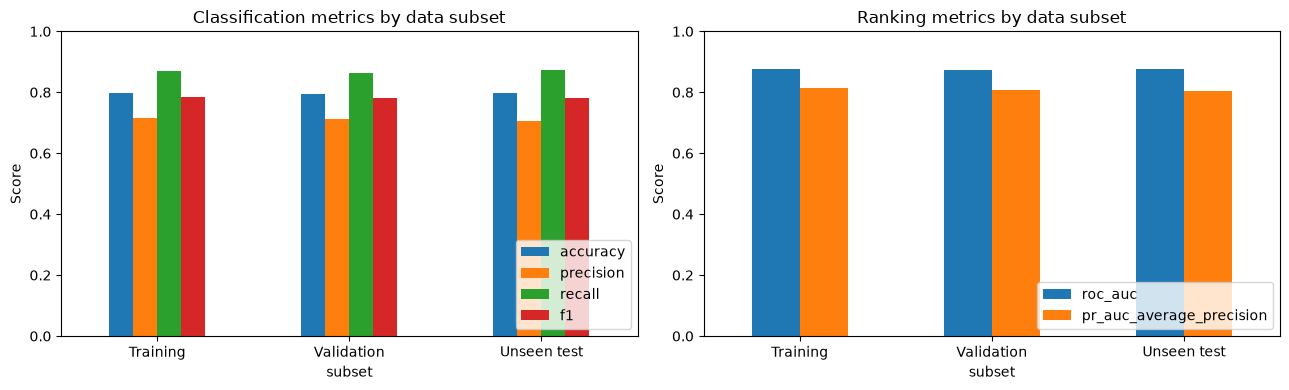

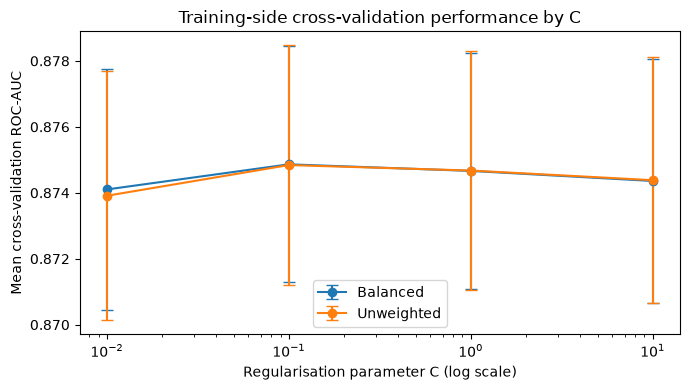

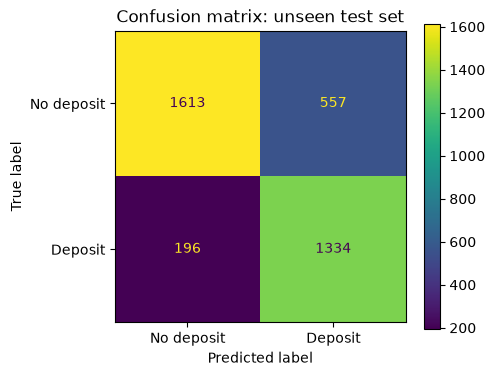

KYC rule test-set operating point
Recall / true-positive rate: 0.8431
False-positive rate: 0.2429
Specificity: 0.7571
Model recall at the KYC false-positive rate: 0.8608


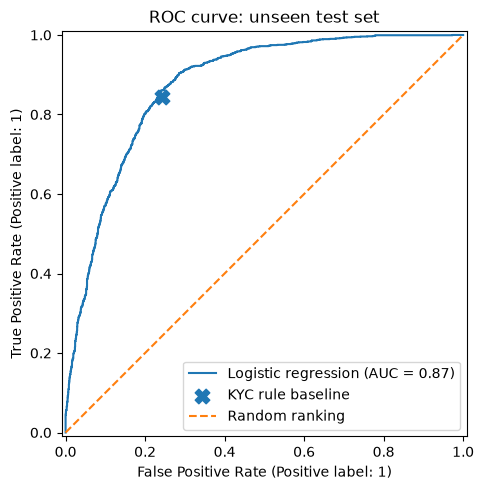


Test-set specificity at model thresholds
Threshold 0.5000: specificity = 0.7502 (75.02%)
Threshold 0.4890: specificity = 0.7433 (74.33%)


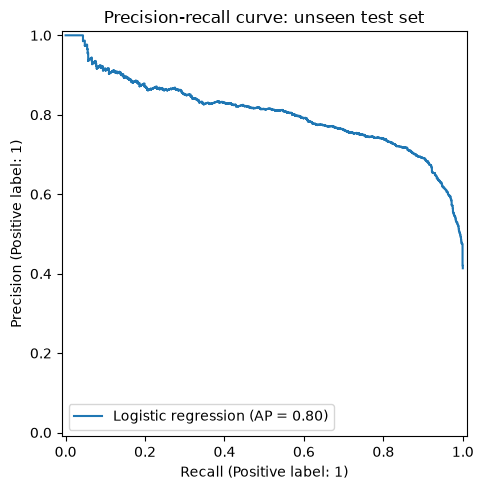

Unseen-test calibration by probability bin (compare predicted probability with observed rate):


,mean_predicted_probability,observed_deposit_rate,observed_minus_predicted
0,0.0436,0.0334,-0.0102
1,0.1462,0.1028,-0.0434
2,0.2469,0.2100,-0.0369
3,0.3491,0.1959,-0.1532
4,0.4554,0.4000,-0.0554
5,0.5538,0.5020,-0.0518
6,0.6556,0.6149,-0.0407
7,0.7523,0.6802,-0.0721
8,0.8494,0.7958,-0.0537
9,0.9285,0.9078,-0.0207


In [9]:
# Compare training, validation and unseen-test classification metrics.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Classification metrics by data subset")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(loc="lower right")

results[["roc_auc", "pr_auc_average_precision"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("Ranking metrics by data subset")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

# Show training-side cross-validation performance by C, with standard-deviation error bars.
cv_plot = pd.DataFrame(search.cv_results_)
cv_plot["C"] = cv_plot["param_model__C"].astype(float)
cv_plot["class_weight_label"] = cv_plot["param_model__class_weight"].map(
    lambda value: "Balanced" if value == "balanced" else "Unweighted"
)
fig, ax = plt.subplots(figsize=(7, 4))
for label, group in cv_plot.groupby("class_weight_label"):
    group = group.sort_values("C")
    ax.errorbar(
        group["C"], group["mean_test_score"], yerr=group["std_test_score"],
        marker="o", capsize=4, label=label
    )
ax.set_xscale("log")
ax.set_xlabel("Regularisation parameter C (log scale)")
ax.set_ylabel("Mean cross-validation ROC-AUC")
ax.set_title("Training-side cross-validation performance by C")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["No deposit", "Deposit"],
    cmap=None, ax=ax
)
ax.set_title("Confusion matrix: unseen test set")
plt.tight_layout()
plt.show()

# Compare the KYC rule and logistic regression on the same unseen test clients.
kyc_pred = (X_test["kyc_status_day3"].astype("string") == "Completed").astype(int)
tn_kyc, fp_kyc, fn_kyc, tp_kyc = confusion_matrix(
    y_test, kyc_pred, labels=[0, 1]
).ravel()
kyc_tpr = tp_kyc / (tp_kyc + fn_kyc)
kyc_fpr = fp_kyc / (fp_kyc + tn_kyc)
kyc_specificity = tn_kyc / (tn_kyc + fp_kyc)

fpr_model, tpr_model, _ = roc_curve(y_test, test_prob)
model_recall_at_kyc_fpr = float(np.interp(kyc_fpr, fpr_model, tpr_model))

print("KYC rule test-set operating point")
print(f"Recall / true-positive rate: {kyc_tpr:.4f}")
print(f"False-positive rate: {kyc_fpr:.4f}")
print(f"Specificity: {kyc_specificity:.4f}")
print(f"Model recall at the KYC false-positive rate: {model_recall_at_kyc_fpr:.4f}")

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=ax, name="Logistic regression")
ax.scatter([kyc_fpr], [kyc_tpr], marker="X", s=110, label="KYC rule baseline")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
ax.set_title("ROC curve: unseen test set")
ax.legend()
plt.tight_layout()
plt.show()

print("\nTest-set specificity at model thresholds")
for threshold in [0.5, best_threshold]:
    threshold_pred = (test_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, threshold_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp)
    print(f"Threshold {threshold:.4f}: specificity = {specificity:.4f} ({specificity:.2%})")

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=ax, name="Logistic regression")
ax.set_title("Precision-recall curve: unseen test set")
plt.tight_layout()
plt.show()

# Inspect calibration numerically as well as visually on the unseen test set.
cal_true, cal_pred = calibration_curve(y_test, test_prob, n_bins=10, strategy="uniform")
calibration_summary = pd.DataFrame({
    "mean_predicted_probability": cal_pred,
    "observed_deposit_rate": cal_true,
    "observed_minus_predicted": cal_true - cal_pred,
})
print("Unseen-test calibration by probability bin (compare predicted probability with observed rate):")
display(calibration_summary.round(4))


## 7. Results and discussion

### 9.1 Model performance and threshold choice

The classification threshold was selected using the validation set by maximising the F1-score, resulting in a threshold of **0.489**. The F1-score balances precision and recall, making it a useful starting point when the business has not specified the relative costs of false-positive and false-negative predictions. Selecting the threshold using validation data also helps keep the unseen test set separate for final evaluation.

On the unseen test set, the logistic regression model achieved an accuracy of **0.7965**, precision of **0.7054**, recall of **0.8719**, and an F1-score of **0.7799**. Its ROC-AUC was **0.8748**, with a bootstrap 95% confidence interval from **0.8641 to 0.8862**. The average precision was **0.8036**, and the Brier score was **0.1418**. These results indicate that the model can distinguish reasonably well between clients who deposit and those who do not, while identifying a high proportion of actual depositors. However, performance may differ for future registrations if client behavior, onboarding processes, or campaign conditions change.

### 9.2 Confusion matrix and business meaning

The confusion matrix should be interpreted using the predictions generated at the selected threshold of **0.489**. It shows four possible outcomes: true negatives, where clients who did not deposit were correctly identified; false positives, where clients were predicted to deposit but did not; false negatives, where clients deposited but were predicted not to; and true positives, where clients who deposited were correctly identified.

The model's recall of **0.8719** means that it identified approximately 87.19% of clients who actually made a deposit within the target period. This may help the business identify potential depositors for targeted onboarding or engagement activities. However, the precision of **0.7054** means that approximately 29.46% of the clients predicted to deposit did not do so. Contacting these clients could result in unnecessary outreach and additional campaign costs.

False negatives also matter because clients who eventually deposit may be missed by the model and therefore not receive targeted support. The appropriate balance between these two types of errors depends on the business objective, available resources, and the relative costs of missing a potential depositor versus contacting a client who does not deposit.

### 9.3 Comparison with the KYC rule baseline

The logistic regression model was compared with a simple KYC rule baseline on the same unseen test set. The baseline predicts a deposit when the client's `kyc_status_day3` value is `Completed`. The KYC baseline achieved an accuracy of **0.7927**, precision of **0.7100**, recall of **0.8431**, and an F1-score of **0.7708**.

Compared with the baseline, the logistic regression model achieved slightly higher accuracy and F1-score, with accuracy increasing from **0.7927 to 0.7965** and F1-score increasing from **0.7708 to 0.7799**. It also achieved higher recall, increasing from **0.8431 to 0.8719**. This means that the model identified a greater proportion of clients who actually deposited. However, the KYC baseline had slightly higher precision, meaning that its positive predictions were somewhat more likely to correspond to actual depositors.

The difference in accuracy between the model and the KYC baseline was **0.0038**. The bootstrap 95% confidence interval for this difference was **−0.0038 to 0.0111**, which includes zero. Therefore, the results do not provide sufficient evidence to conclude that the logistic regression model has a clear accuracy advantage over the KYC rule on this test set.

The logistic regression model also provides predicted probabilities, allowing clients to be ranked according to their likelihood of depositing and enabling the business to adjust the classification threshold. The KYC rule produces a binary prediction based on a single field. At the KYC baseline’s false-positive rate of **0.2429**, the model’s estimated recall was **0.8608**, compared with baseline recall of **0.8431**. This is a modest improvement of **1.77 percentage points** at the same false-positive rate, and its operational value depends on the business’s objectives and intervention capacity.

Overall, the logistic regression model shows potential as a complement to the KYC rule, particularly when the business wants to rank clients and adjust targeting decisions. However, the results do not establish that it should replace the existing rule. Further evaluation would be needed to determine whether the differences produce meaningful business benefits.

### 9.4 Limitations and recommendations

Although the logistic regression model achieved reasonable classification and ranking performance, several limitations should be considered.

**Changes in client behavior over time.** Client behavior, marketing campaigns, and onboarding processes may change. A model trained on historical registrations may become less accurate as these conditions change. Its performance should therefore be monitored on newer data, with particular attention to changes in recall, precision, ROC-AUC, and calibration.

**Threshold selection depends on business priorities.** The threshold of **0.489** was selected by maximising validation F1-score. Although this balances precision and recall, it does not directly account for the financial costs of false positives and false negatives or the number of clients the business can contact. The final operational threshold should be reviewed against campaign objectives, intervention capacity, and the cost of different prediction errors.

**Comparison with the KYC baseline.** The model's accuracy was only slightly higher than the KYC baseline, and the confidence interval for the accuracy difference included zero. Therefore, the model should not be assumed to be more accurate overall. Further comparison should consider business costs, recall, precision, and the usefulness of predicted probabilities rather than relying on accuracy alone.

**Probability calibration.** The Brier score of **0.1418** provides an overall measure of the accuracy of the predicted probabilities, with lower values indicating better probabilistic predictions. The calibration plot and the printed calibration-bin table should be read together: predicted probabilities are well calibrated when each bin’s observed deposit rate is close to its mean predicted probability. Points above the diagonal indicate that observed rates exceed predicted rates (underprediction), while points below it indicate overprediction. Because balanced class weights can shift probability estimates, the plot should be checked after the notebook is rerun rather than assuming that the probabilities are calibrated. The Brier score of 0.1418 is a useful overall measure, but by itself it does not show where calibration errors occur.

**Generalisation to future clients.** The test results describe performance on the available unseen test set and do not guarantee the same performance in future campaigns or client populations. Additional evaluation on more recent data would help determine whether the model remains reliable.

The model should also be reviewed for differences in error rates across relevant client groups before deployment. Only necessary client information should be used, access to client data should be restricted, and any use of predictions for targeting should follow applicable privacy requirements, including POPIA.

Based on these findings, the model should initially be used as a decision-support tool alongside the existing KYC rule. The business should monitor performance over time, evaluate the cost of false positives and false negatives, review probability calibration, and select an operational threshold based on its campaign objectives. A controlled trial could then assess whether model-guided targeting improves deposit outcomes compared with the existing approach.
